In [1]:
import copy
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch as th
import torch.nn.functional as F
from sklearn.metrics import average_precision_score, confusion_matrix, roc_auc_score
from sklearn.preprocessing import LabelEncoder
from torch import nn
from torch_geometric.nn import GAE, VGAE, GATConv, GCNConv, SAGEConv

In [2]:
# Données générées par le notebook 0_import_data (split train / val / test fait )

train_data = th.load('../data/train_data_3.pt', weights_only=False)
val_data = th.load('../data/val_data_3.pt', weights_only=False)
test_data = th.load('../data/test_data_3.pt', weights_only=False)
data = th.load('../data/data_3.pt', weights_only=False)

# on vérifie les données chargées
print(test_data)
print(f"\nFeatures des nœuds : [longitude, latitude, population] -> {data.num_features} features")
print(f"\nFeatures des nœuds : [longitude, latitude, population] -> {train_data.num_features} features")

# Paramètres communs à toutes les expériences, cest paramètres pourront varier localement selon les besoins
HIDDEN, DIM_OUT, EPOCHS, LR = 128, 16, 300, 0.01  # configuration du modèle final
SEEDS = [0, 1, 2]

Data(edge_index=[2, 21676], country=[3363], city_name=[3363], x=[3363, 216], pos_edge_label=[2709], pos_edge_label_index=[2, 2709], neg_edge_label=[2709], neg_edge_label_index=[2, 2709])

Features des nœuds : [longitude, latitude, population] -> 216 features

Features des nœuds : [longitude, latitude, population] -> 216 features


In [ ]:
# Définition de l'encodeur et des fonctions d'entraînement et de test pour les modèles


class Encoder(nn.Module):
    def __init__(self, dim_in, hidden_channels, dim_out, conv=GCNConv):
        super(Encoder, self).__init__()
        self.conv1 = conv(dim_in, hidden_channels)
        self.conv_mu = conv(hidden_channels, dim_out)
        self.conv_logstd = conv(hidden_channels, dim_out)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index).relu()
        mu = self.conv_mu(x, edge_index)
        logstd = self.conv_logstd(x, edge_index)
        return mu, logstd


class EncoderGAE(nn.Module):
    def __init__(self, dim_in, hidden_channels, dim_out, conv=GCNConv):
        super().__init__()
        self.conv1 = conv(dim_in, hidden_channels)
        self.conv2 = conv(hidden_channels, dim_out)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index).relu()
        return self.conv2(x, edge_index)  

class EncoderVGAE1Couche(nn.Module):
    def __init__(self, dim_in, hidden_channels, dim_out, conv=GCNConv):
        super().__init__()
        self.conv_mu = conv(dim_in, dim_out)  # hidden_channels non utilisé : pas de couche cachée
        self.conv_logstd = conv(dim_in, dim_out)

    def forward(self, x, edge_index):
        return self.conv_mu(x, edge_index), self.conv_logstd(x, edge_index)



def terme_kl(model, donnees):
    # terme KL : seulement pour le VGAE (le GAE n'a pas de partie variationnelle)
    return model.kl_loss() / donnees.num_nodes if isinstance(model, VGAE) else 0


def entrainer_et_tester(model, optimizer, epochs, train_data, val_data, test_data, patience=50):
    history = {"train": [], "val": []}
    meilleure_auc_val, meilleure_ap_val, meilleur_etat, meilleure_epoch = -1, None, None, None
    epochs_sans_amelioration = 0
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        z = model.encode(train_data.x, train_data.edge_index)
        loss = model.recon_loss(
            z, train_data.pos_edge_label_index, train_data.neg_edge_label_index
        ) + terme_kl(model, train_data)
        loss.backward()
        optimizer.step()
        history["train"].append(loss.item())

        # validation : pas de calcul de gradient mais on calcule la loss sur les données de validation
        model.eval()
        with th.no_grad():
            z_val = model.encode(val_data.x, val_data.edge_index)
            val_loss = model.recon_loss(
                z_val, val_data.pos_edge_label_index, val_data.neg_edge_label_index
            ) + terme_kl(model, val_data)
            history["val"].append(val_loss.item())
            auc_val, ap_val = model.test(z_val, val_data.pos_edge_label_index, val_data.neg_edge_label_index)
            if auc_val > meilleure_auc_val:
                meilleure_auc_val, meilleure_ap_val, meilleur_etat = auc_val, ap_val, copy.deepcopy(model.state_dict())
                meilleure_epoch = epoch + 1
                epochs_sans_amelioration = 0
            else:
                epochs_sans_amelioration += 1

        # early stopping : l'AUC val ne s'est pas améliorée depuis `patience` epochs
        if epochs_sans_amelioration >= patience:
            break

    # évaluation sur le test avec le meilleur modèle (choisi sur la validation)
    model.load_state_dict(meilleur_etat)
    model.eval()
    with th.no_grad():
        z_test = model.encode(test_data.x, test_data.edge_index)
        auc_test, ap_test = model.test(z_test, test_data.pos_edge_label_index, test_data.neg_edge_label_index)
    return history, auc_test, ap_test, meilleure_auc_val, meilleure_ap_val, meilleure_epoch


def lancer_experience(splits, conv=GCNConv, hidden_channels=HIDDEN, dim_out=DIM_OUT, EPOCHS=EPOCHS, LR=LR,
                      patience=50, modele_cls=VGAE, encodeur=Encoder):
    # un entraînement par seed ; renvoie les résultats test, l'historique et le modèle de la première seed
    resultats, historique, modele = [], None, None
    for seed in SEEDS:
        th.manual_seed(seed)
        model = modele_cls(encodeur(splits[0].num_features, hidden_channels, dim_out, conv))
        optimizer = th.optim.Adam(model.parameters(), lr=LR)
        debut = time.perf_counter()
        history, auc, ap, auc_val, ap_val, meilleure_epoch = entrainer_et_tester(
            model, optimizer, EPOCHS, *splits, patience=patience)
        temps = time.perf_counter() - debut  # temps d'entraînement + test (en secondes)
        resultats.append({"seed": seed, "AUC val": auc_val, "AP val": ap_val, "meilleure epoch": meilleure_epoch,
                          "epochs effectuées": len(history["train"]),
                          "AUC": auc, "AP": ap, "temps (s)": temps})
        if seed == SEEDS[0]:
            historique, modele = history, model
    return resultats, historique, modele


def afficher_resultats(nom, resultats):
    # AUC et AP de validation par seed (moyenne ± écart-type), meilleures epochs, epochs effectuées et temps moyen
    texte = f"{nom} :"
    for metrique in ["AUC val", "AP val"]:
        valeurs = [r[metrique] for r in resultats]
        texte += (f" {metrique} = " + ", ".join(f"{v:.4f}" for v in valeurs)
                  + f" (moyenne = {np.mean(valeurs):.4f} ± {np.std(valeurs, ddof=1):.4f}) |")
    texte += (f" meilleures epochs = {[r['meilleure epoch'] for r in resultats]}"
              + f" | epochs effectuées = {[r['epochs effectuées'] for r in resultats]}"
              + f" (moyenne = {np.mean([r['epochs effectuées'] for r in resultats]):.0f})"
              + f" | temps moyen = {np.mean([r['temps (s)'] for r in resultats]):.2f} s")
    print(texte)


In [ ]:
def tracer_loss(historiques, titre):
    # courbes de loss train (trait plein) et validation (pointillés), échelle log
    plt.figure(figsize=(8, 4))
    for nom, history in historiques.items():
        ligne, = plt.plot(history["train"], label=f"{nom} train")
        plt.plot(history["val"], linestyle="--", color=ligne.get_color(), label=f"{nom} val")
    plt.yscale("log")
    plt.xlabel("Epochs")
    plt.ylabel("Loss (échelle log)")
    plt.title(titre)
    plt.legend(fontsize=8)
    plt.show()

VGAE (modèle final) : AUC val = 0.9784, 0.9755, 0.9786 (moyenne = 0.9775 ± 0.0017) | AP val = 0.9795, 0.9765, 0.9796 (moyenne = 0.9785 ± 0.0017) | meilleures epochs = [102, 40, 78] | epochs effectuées = [152, 90, 128] (moyenne = 123) | temps moyen = 1.50 s
GAE : AUC val = 0.9740, 0.9755, 0.9760 (moyenne = 0.9751 ± 0.0010) | AP val = 0.9741, 0.9763, 0.9758 (moyenne = 0.9754 ± 0.0012) | meilleures epochs = [54, 66, 52] | epochs effectuées = [104, 116, 102] (moyenne = 107) | temps moyen = 1.03 s
VGAE 1 couche : AUC val = 0.9782, 0.9782, 0.9790 (moyenne = 0.9785 ± 0.0004) | AP val = 0.9783, 0.9780, 0.9785 (moyenne = 0.9783 ± 0.0003) | meilleures epochs = [189, 209, 204] | epochs effectuées = [239, 259, 254] (moyenne = 251) | temps moyen = 1.71 s


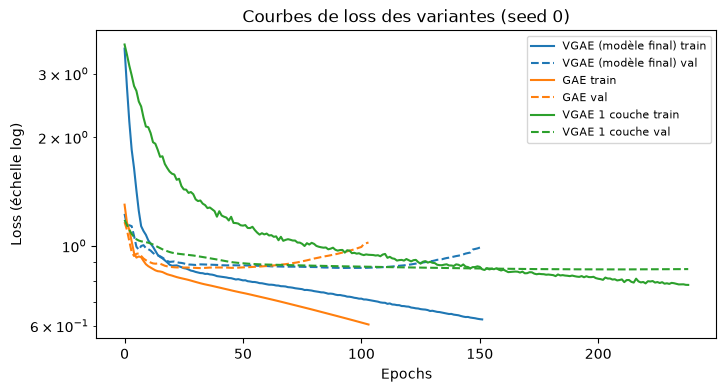

AUC val          AP val             AUC              AP  \
                       mean     std    mean     std    mean     std    mean   
variante                                                                      
VGAE (modèle final)  0.9775  0.0017  0.9785  0.0017  0.9729  0.0012  0.9754   
GAE                  0.9751  0.0010  0.9754  0.0012  0.9731  0.0007  0.9757   
VGAE 1 couche        0.9785  0.0004  0.9783  0.0003  0.9717  0.0004  0.9753   

                            epochs effectuées          temps (s)          
                        std              mean      std      mean     std  
variante                                                                  
VGAE (modèle final)  0.0016          123.3333  31.2623    1.4993  0.3150  
GAE                  0.0006          107.3333   7.5719    1.0273  0.1290  
VGAE 1 couche        0.0001          250.6667  10.4083    1.7119  0.0541

In [ ]:
# Ablations : VGAE -> GAE (on retire la partie variationnelle : pas de mu / logstd, pas de terme KL)
#             VGAE -> VGAE 1 couche (on retire la couche cachée)
splits = (train_data, val_data, test_data)
variantes = {
    "VGAE (modèle final)": (VGAE, Encoder),
    "GAE": (GAE, EncoderGAE),
    "VGAE 1 couche": (VGAE, EncoderVGAE1Couche),
}

resultats_ablation, historiques_ablation = [], {}
for nom, (modele_cls, encodeur) in variantes.items():
    resultats, historiques_ablation[nom], _ = lancer_experience(
        splits, GCNConv, hidden_channels=128, dim_out=16, EPOCHS=300, LR=0.01, patience=50,
        modele_cls=modele_cls, encodeur=encodeur)
    resultats_ablation += [{"variante": nom, **r} for r in resultats]
    afficher_resultats(nom, resultats)

tracer_loss(historiques_ablation, "Courbes de loss des variantes (seed 0)")



data_0 (3 features) : AUC val = 0.7355, 0.5000, 0.7296 (moyenne = 0.6550 ± 0.1343) | AP val = 0.6559, 0.5000, 0.6508 (moyenne = 0.6022 ± 0.0886) | meilleures epochs = [234, 1, 192] | epochs effectuées = [284, 51, 242] (moyenne = 192) | temps moyen = 2.08 s
data_1 (3 features) : AUC val = 0.9709, 0.9691, 0.9689 (moyenne = 0.9696 ± 0.0011) | AP val = 0.9724, 0.9704, 0.9709 (moyenne = 0.9712 ± 0.0011) | meilleures epochs = [298, 293, 290] | epochs effectuées = [300, 300, 300] (moyenne = 300) | temps moyen = 3.25 s
data_2 (4 features) : AUC val = 0.9778, 0.9751, 0.9758 (moyenne = 0.9762 ± 0.0014) | AP val = 0.9785, 0.9758, 0.9765 (moyenne = 0.9769 ± 0.0014) | meilleures epochs = [287, 216, 222] | epochs effectuées = [300, 266, 272] (moyenne = 279) | temps moyen = 2.95 s
data_3 (216 features) : AUC val = 0.9784, 0.9755, 0.9786 (moyenne = 0.9775 ± 0.0017) | AP val = 0.9795, 0.9765, 0.9796 (moyenne = 0.9785 ± 0.0017) | meilleures epochs = [102, 40, 78] | epochs effectuées = [152, 90, 128] (mo

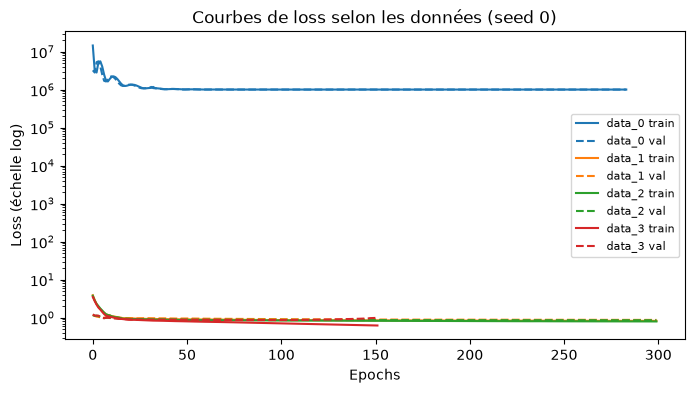

In [ ]:
# Ablation des données : le modèle choisi est entraîné sur chaque jeu de features du notebook 0
# les 4 jeux partagent exactement le même split (mêmes arêtes en train / val / test), seules les features changent

jeux_de_donnees = {
    "data_0": 0,
    "data_1": 1,
    "data_2": 2,
    "data_3": 3,
}

resultats_donnees, historiques_donnees = [], {}
for nom, k in jeux_de_donnees.items():
    splits_k = tuple(th.load(f"../data/{partie}_data_{k}.pt", weights_only=False) for partie in ("train", "val", "test"))
    resultats, historiques_donnees[nom], _ = lancer_experience(
        splits_k, GCNConv, hidden_channels=128, dim_out=16, EPOCHS=300, LR=0.01, patience=50,
        modele_cls=VGAE, encodeur=Encoder)
    resultats_donnees += [{"données": nom, "nb features": splits_k[0].num_features, **r} for r in resultats]
    afficher_resultats(f"{nom} ({splits_k[0].num_features} features)", resultats)

tracer_loss(historiques_donnees, "Courbes de loss selon les données (seed 0)")
